<h1 style="text-align: center;">ETTh2 Transformer Temperature Tracker</strong>

<div style="position: relative; text-align: center;">
  <strong style="position: absolute; left: 0;">Authors:</strong>
  Jan Wodnicki · Jacob Isho · James Gillbank
</div>

### ETTH2 dataset

#### Raw Data Preview

In [7]:
# Initial setup required for loading the CSV file and plotting the data.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Load the CSV from the same folder as this notebook.
df = pd.read_csv("ETTh2.csv", parse_dates=["date"])

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()

Loaded 17,420 rows and 8 columns.


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001
2,2016-07-01 02:00:00,37.946999,11.309,35.330002,9.007,2.100,0.000,36.465000
3,2016-07-01 03:00:00,38.952000,11.895,35.543999,9.436,3.380,1.215,33.608501
4,2016-07-01 04:00:00,38.113998,11.476,35.410000,9.623,2.036,0.000,31.850500


The table below explains the acronyms used inside the dataset:

| **HUFL** | **HULL** | **MUFL** | **MULL** | **LUFL** | **LULL** | **OT** |
|----------|----------|----------|----------|----------|----------|--------|
| High Useful Load | High Useless Load | Middle Useful Load | Middle Useless Load | Low Useful Load | Low Useless Load | Oil Temperature |

**Prediction target:** `OT` represents the transformer's oil temperature, which we aim to predict using the changing load measurements.

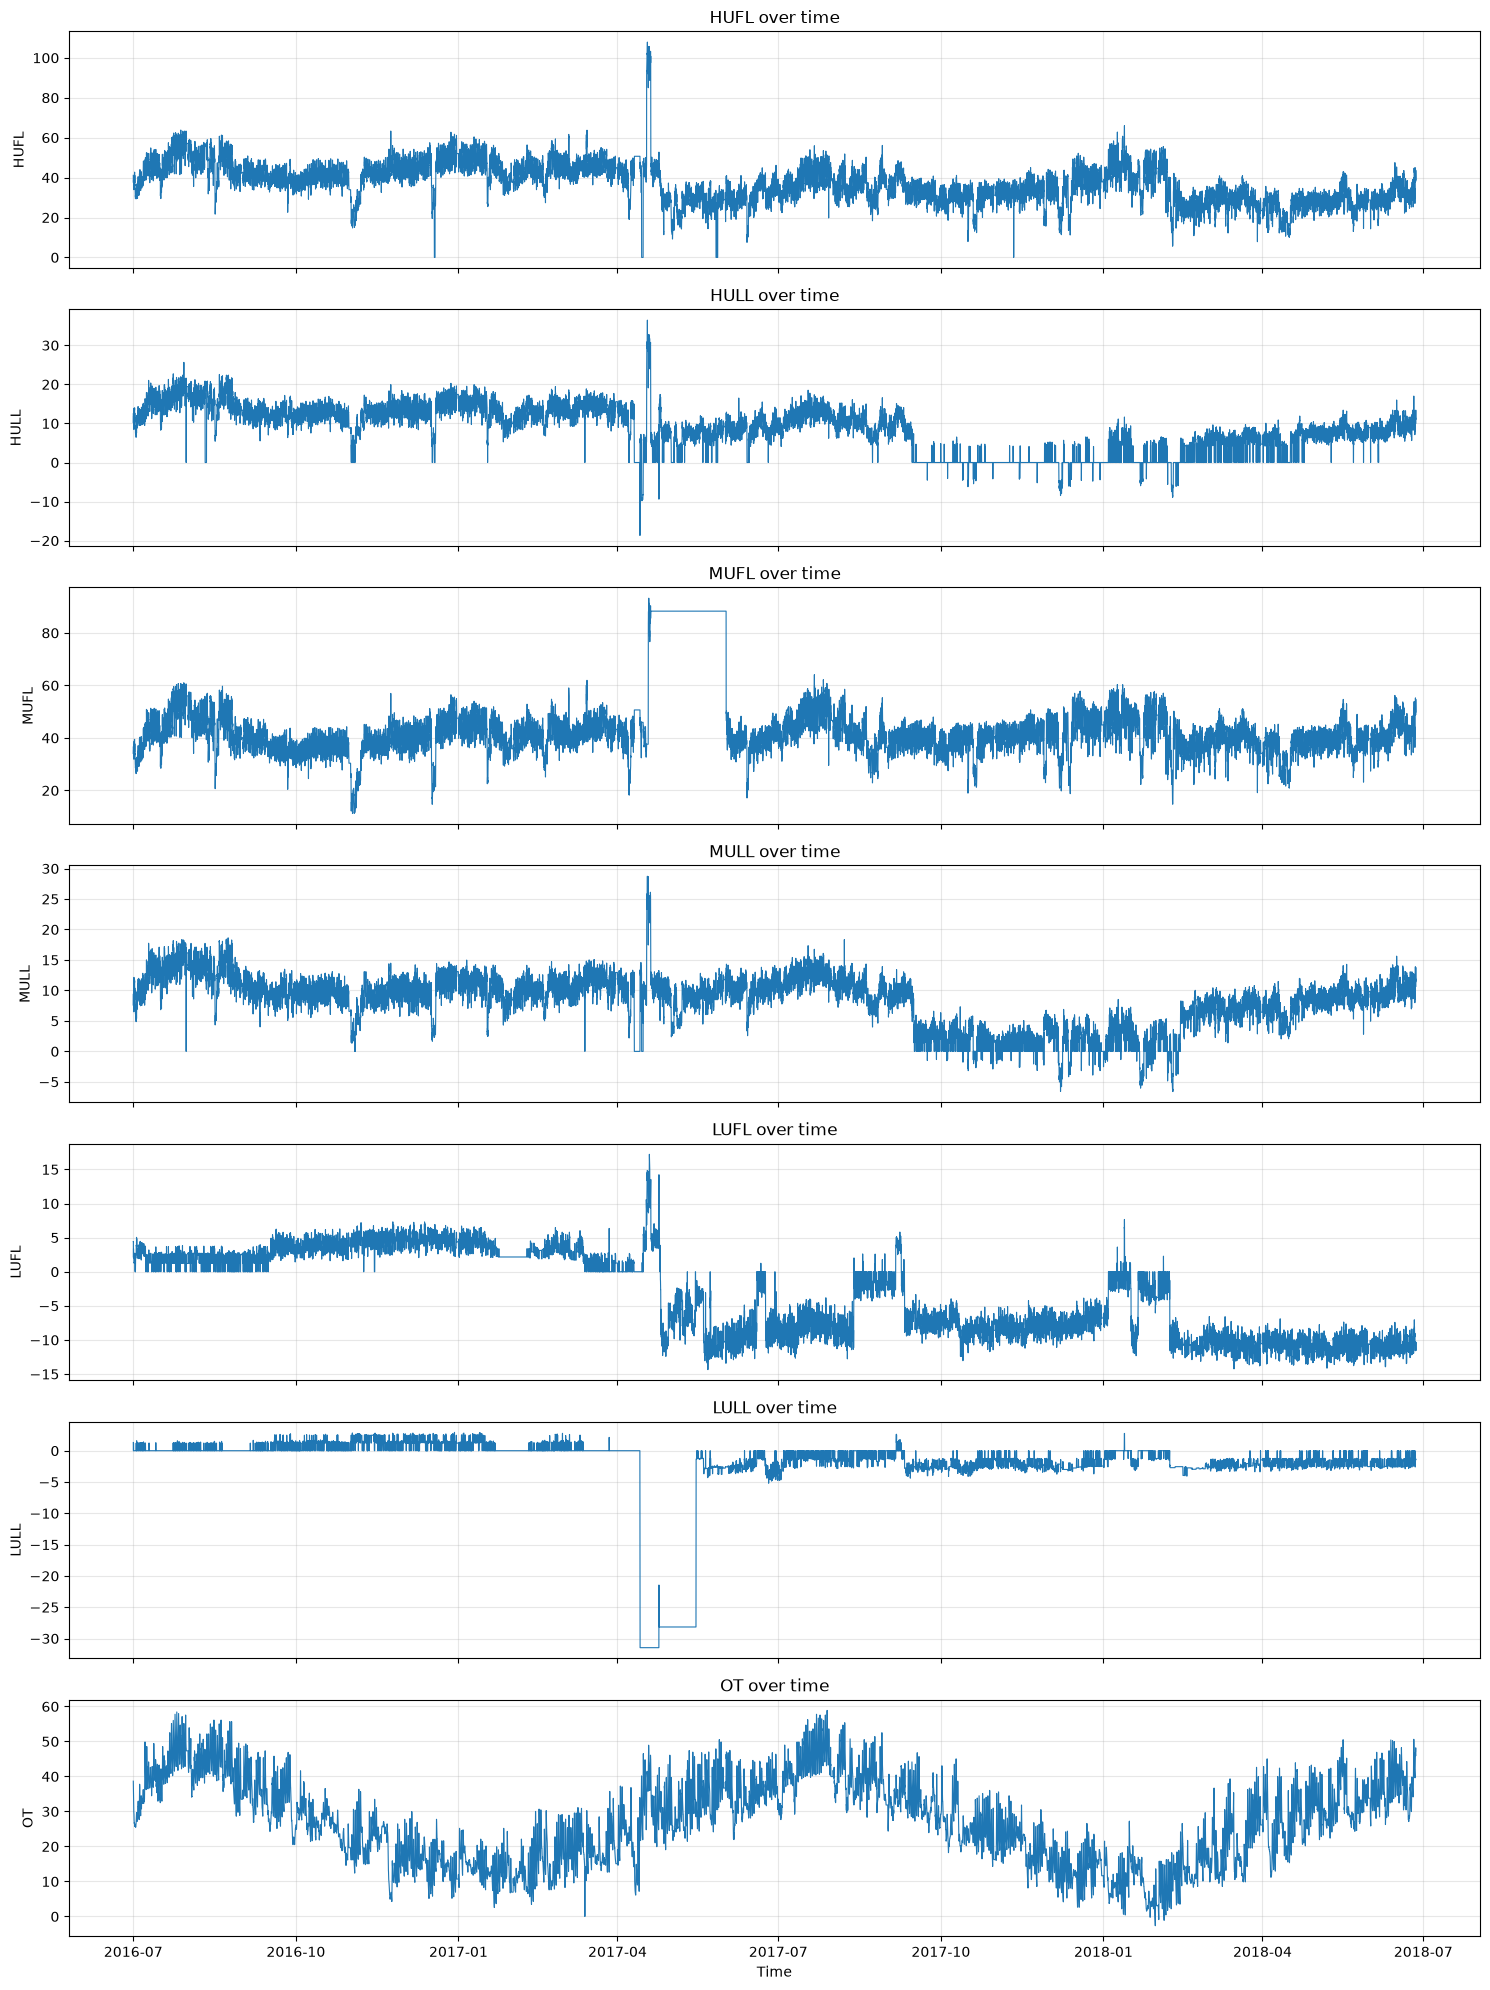

In [8]:
# Plot all variables over time.

variables = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]

fig, axes = plt.subplots(7, 1, figsize=(15, 20), sharex=True)

for ax, variable in zip(axes, variables):
    ax.plot(df["date"], df[variable], linewidth=0.8)
    ax.set_title(f"{variable} over time")
    ax.set_ylabel(variable)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

#### Preprocessing and Data Split

In [11]:
data = df.copy()

# Validate timestamps and put observations in chronological order.
data["date"] = pd.to_datetime(data["date"], errors="coerce")

if data["date"].isna().any():
    raise ValueError("Missing or invalid timestamps must be corrected first.")

data = data.sort_values("date").set_index("date")

# Convert measurements to numbers; treat invalid/infinite values as missing.
variables = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]
data[variables] = (
    data[variables]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

# Report missing values and drop any affected measurement columns.
missing_counts = data[variables].isna().sum()
print("Missing values per column:")
print(missing_counts)

columns_to_drop = missing_counts[missing_counts > 0].index.tolist()
data = data.drop(columns=columns_to_drop)
print("\nDropped columns:", columns_to_drop or "None")

if "OT" in columns_to_drop:
    print("WARNING: OT was dropped; it is needed for temperature prediction.")


# Using the 60/20/20 split for training, validation, and testing.
# This was defined inside the project description requirements. 
n = len(data)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = data.iloc[:train_end].copy()
val_raw   = data.iloc[train_end:val_end].copy()
test_raw  = data.iloc[val_end:].copy()

for name, split in [
    ("Train", train_raw),
    ("Val", val_raw),
    ("Test", test_raw),
]:
    print(
        f"{name:5}: {len(split):,} rows | "
        f"{split.index.min()} to {split.index.max()}"
    )


Missing values per column:
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64

Dropped columns: None
Train: 10,452 rows | 2016-07-01 00:00:00 to 2017-09-09 11:00:00
Val  : 3,484 rows | 2017-09-09 12:00:00 to 2018-02-01 15:00:00
Test : 3,484 rows | 2018-02-01 16:00:00 to 2018-06-26 19:00:00


#### Oil Temperature Data Split Visualized

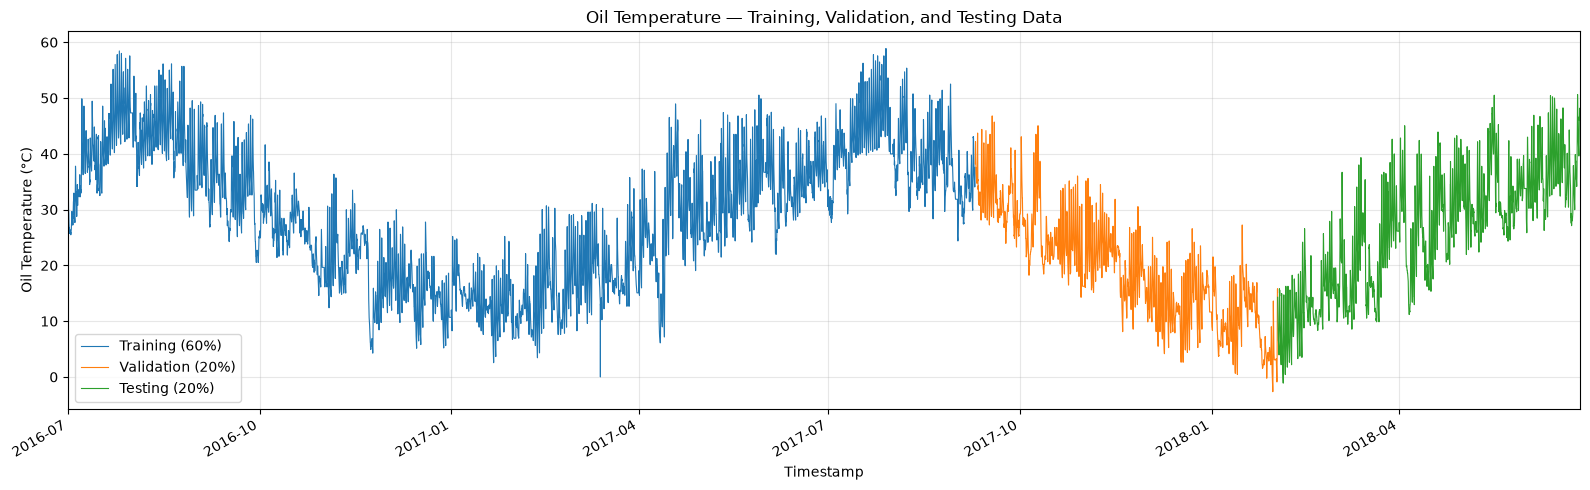

In [16]:
# Oil Temperature split plot visualization
fig, ax = plt.subplots(figsize=(16, 5))

for label, split, color in [
    ("Training (60%)", train_raw, "tab:blue"),
    ("Validation (20%)", val_raw, "tab:orange"),
    ("Testing (20%)", test_raw, "tab:green"),
]:
    ax.plot(
        split.index,
        split["OT"],
        color=color,
        label=label,
        linewidth=0.8,
    )

ax.set(
    title="Oil Temperature — Training, Validation, and Testing Data",
    xlabel="Timestamp",
    ylabel="Oil Temperature (°C)",
    xlim=(train_raw.index.min(), test_raw.index.max()),
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()



#### Normalized Data

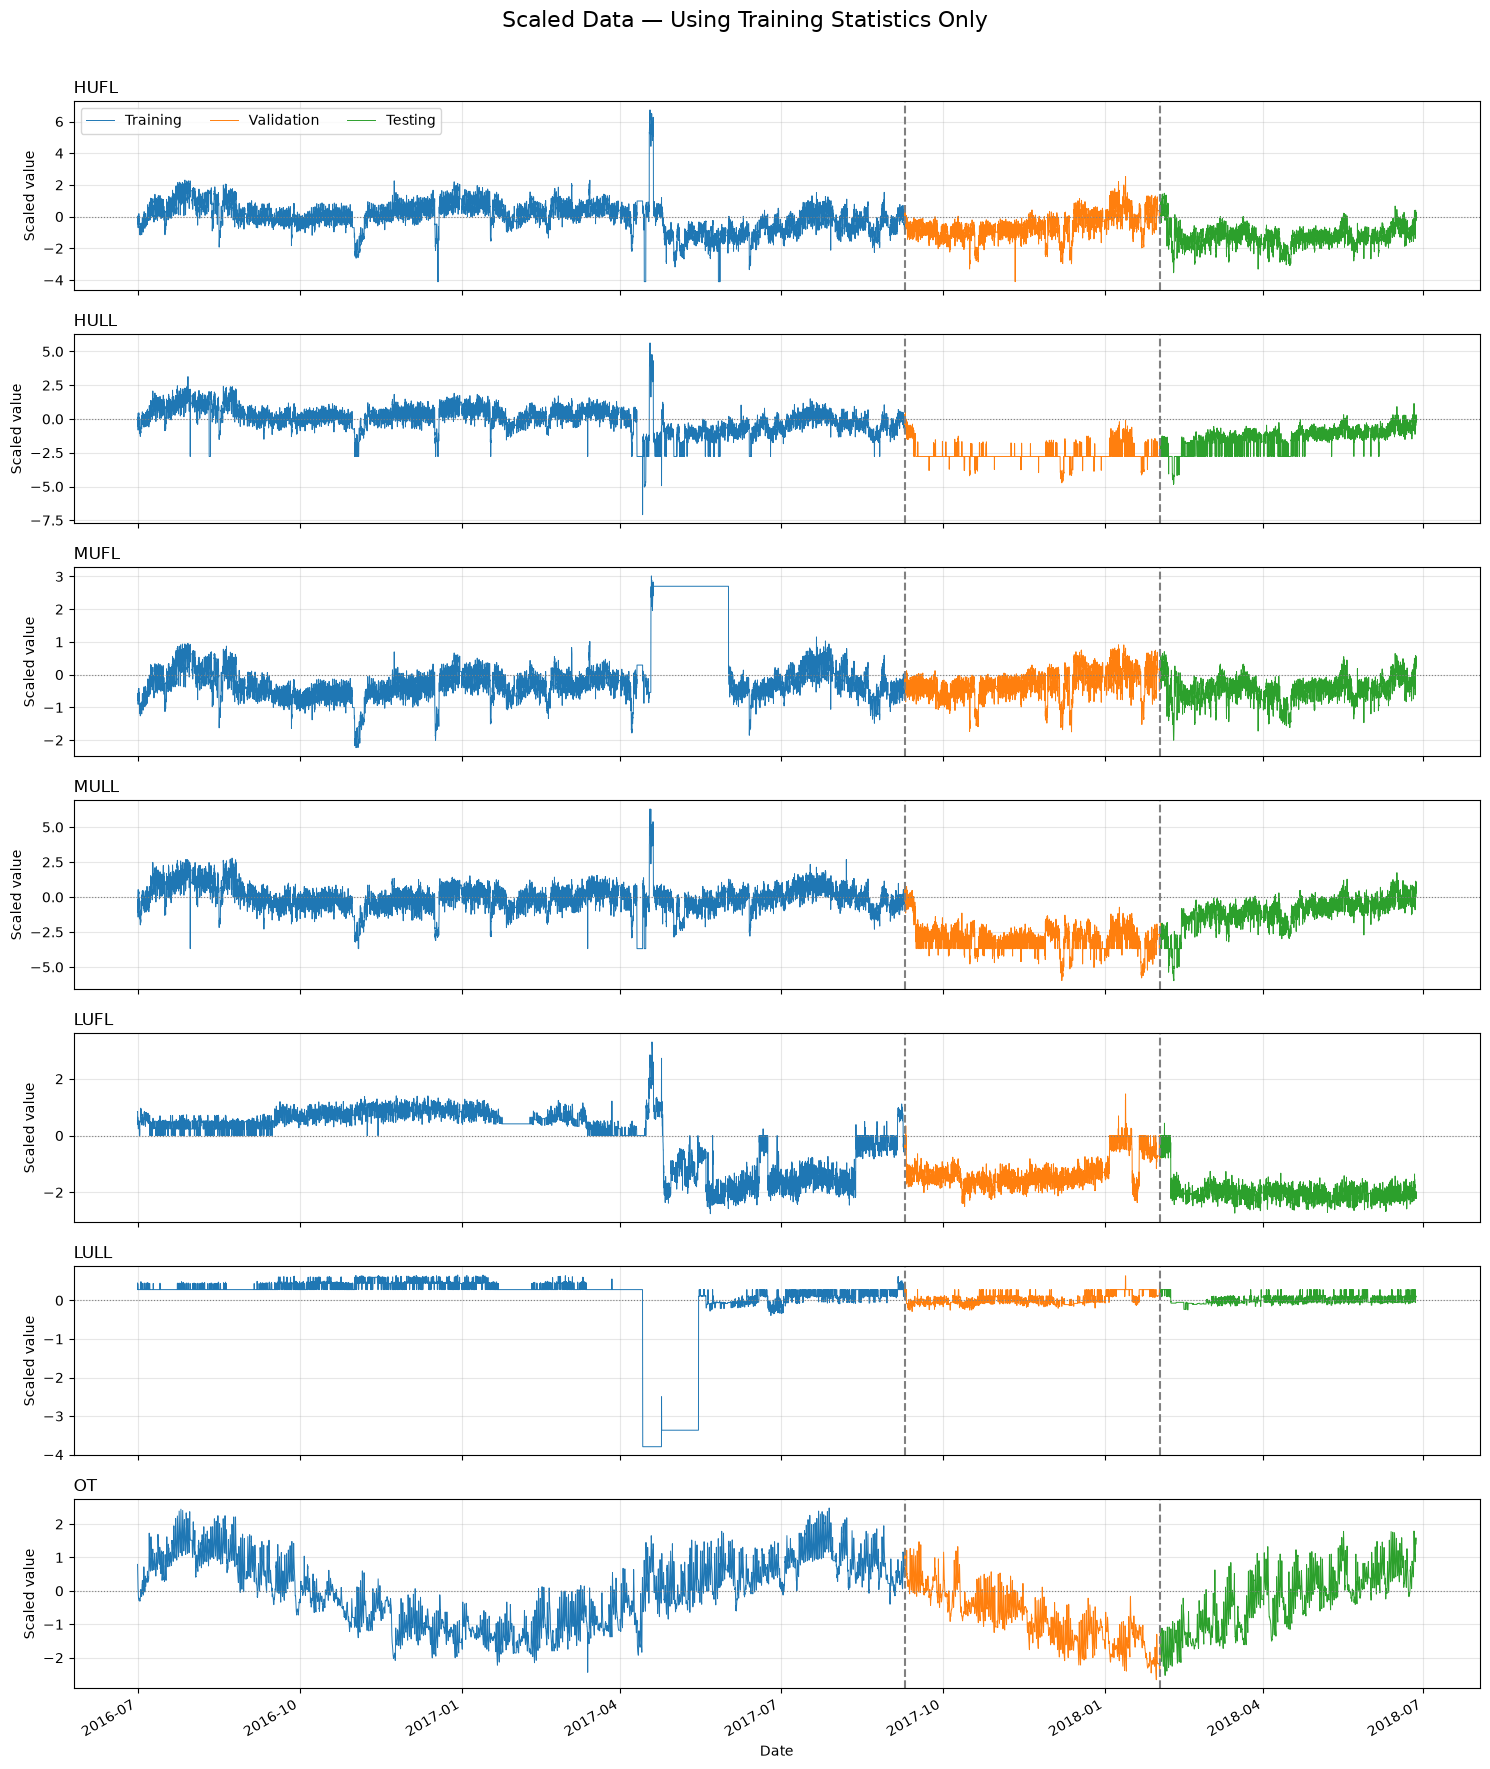

In [15]:
# Calculate scaling parameters from training data only.
train_mean = train_raw.mean()
train_std = train_raw.std()

# Avoid division by zero for constant columns.
train_std = train_std.replace(0, 1)

# Apply the SAME parameters to all three splits.
train_scaled = (train_raw - train_mean) / train_std
val_scaled = (val_raw - train_mean) / train_std
test_scaled = (test_raw - train_mean) / train_std


# Inspect training statistics.
# print("Scaled training statistics:")

# print(pd.DataFrame({
#    "Mean": train_scaled.mean(),
#    "Standard deviation": train_scaled.std(),
# }).round(4))

# Convert scaled OT predictions back to the original temperature units.
def inverse_scale_ot(predictions):
    return np.asarray(predictions) * train_std["OT"] + train_mean["OT"]


# Plot the scaled data for all three splits.
import matplotlib.pyplot as plt

variables = train_scaled.columns

fig, axes = plt.subplots(
    len(variables), 1,
    figsize=(15, 18),
    sharex=True,
    squeeze=False,
)

for ax, variable in zip(axes[:, 0], variables):
    for label, split, color in [
        ("Training", train_scaled, "tab:blue"),
        ("Validation", val_scaled, "tab:orange"),
        ("Testing", test_scaled, "tab:green"),
    ]:
        ax.plot(
            split.index, split[variable],
            label=label, color=color, linewidth=0.7,
        )

    ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
    ax.axvline(val_scaled.index[0], color="gray", linestyle="--")
    ax.axvline(test_scaled.index[0], color="gray", linestyle="--")
    ax.set_title(variable, loc="left")
    ax.set_ylabel("Scaled value")
    ax.grid(True, alpha=0.3)

axes[0, 0].legend(ncol=3)
axes[-1, 0].set_xlabel("Date")

fig.suptitle("Scaled Data — Using Training Statistics Only", fontsize=16)
fig.autofmt_xdate()
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


#### Stationarity?


### Stage 1 - Baseline and Traditional ML Models


#### Baselines


##### Seasonal Naive



To establish a seasonal naive the assumption is that the seasonality of the data has a lag of 24, relating to the difference of Oil Temperature 24 hours apart. The SN model, visually appears to map itself quite well with the testing data, and has an MAE of 3.53°C and an RMSE of 4.77°C of error. These values are respectable baseline to contrast more sophisticated model architectures.

Daily seasonal naive performance:
               MAE    RMSE
Split                     
Validation  2.8193  3.8180
Testing     3.5256  4.7721


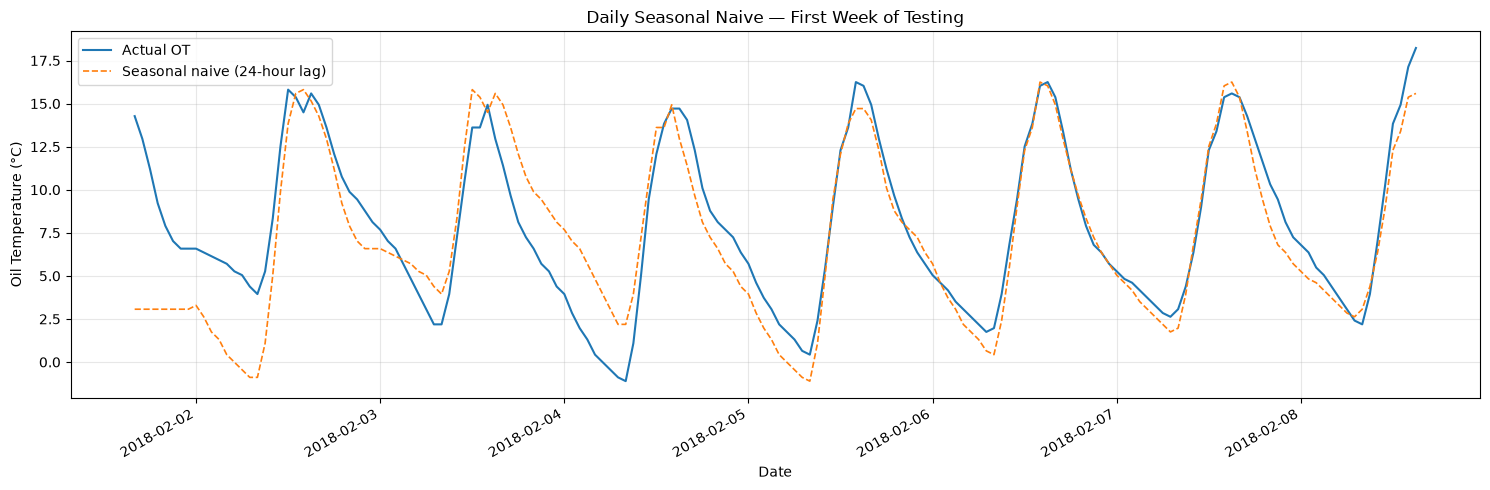

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seasonal_period = 24  # Hourly data: 24 = daily, 168 = weekly

# Include past observations across split boundaries.
ot = pd.concat([
    train_raw["OT"],
    val_raw["OT"],
    test_raw["OT"],
])

seasonal_predictions = ot.shift(seasonal_period)

# Evaluate validation and test predictions.
results = []

for name, split in [
    ("Validation", val_raw),
    ("Testing", test_raw),
]:
    actual = split["OT"]
    predicted = seasonal_predictions.reindex(actual.index)

    if predicted.isna().any():
        raise ValueError("Insufficient history for the seasonal period.")

    errors = actual - predicted

    results.append({
        "Split": name,
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    })

print("Daily seasonal naive performance:")
print(pd.DataFrame(results).set_index("Split").round(4))

# Display the first seven days of testing.
actual = test_raw["OT"].iloc[:168]
predicted = seasonal_predictions.reindex(actual.index)

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(actual.index, actual, label="Actual OT", linewidth=1.5)
ax.plot(
    predicted.index, predicted,
    label="Seasonal naive (24-hour lag)",
    linestyle="--", linewidth=1.2,
)

ax.set(
    title="Daily Seasonal Naive — First Week of Testing",
    xlabel="Date",
    ylabel="Oil Temperature (°C)",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

##### Mean

To establish the mean baseline, the average Oil Temperature was calculated from the training data. It was then plotted against the first week of the testing data, where it shows how a fixed prediction is uneffective at predicting the Oil Temperatures which changes throughout the year. The results display an MAE of 9.02°C and an RMSE of 11.41 °C of error, showing the unreliability of this prediction model.

Training mean OT: 29.1780 °C

Mean baseline performance:
                MAE     RMSE
Split                       
Validation  11.3894  13.6091
Testing      9.0242  11.1410


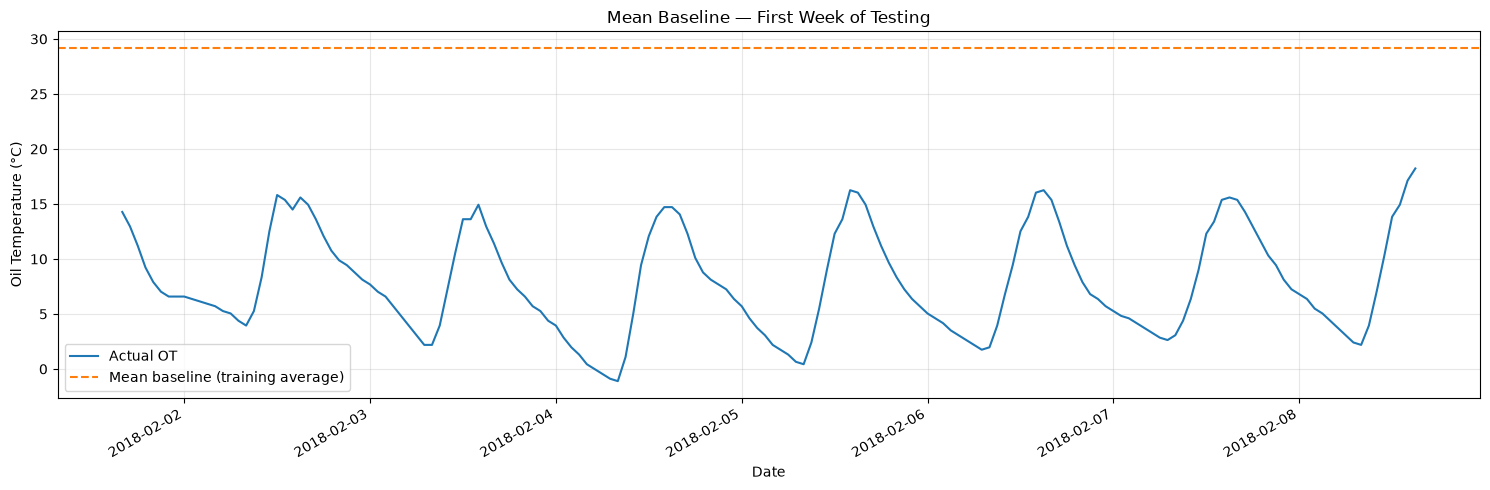

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the baseline using training data only.
mean_ot = train_raw["OT"].mean()

results = []

for name, split in [
    ("Validation", val_raw),
    ("Testing", test_raw),
]:
    actual = split["OT"]
    predicted = np.full(len(actual), mean_ot)
    errors = actual - predicted

    results.append({
        "Split": name,
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
    })

print(f"Training mean OT: {mean_ot:.4f} °C")
print("\nMean baseline performance:")
print(pd.DataFrame(results).set_index("Split").round(4))

# Display the first seven days of testing.
actual = test_raw["OT"].iloc[:168]

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(actual.index, actual, label="Actual OT", linewidth=1.5)
ax.axhline(
    mean_ot,
    label="Mean baseline (training average)",
    color="tab:orange",
    linestyle="--",
    linewidth=1.5,
)

ax.set(
    title="Mean Baseline — First Week of Testing",
    xlabel="Date",
    ylabel="Oil Temperature (°C)",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

#### MLP Model 

#### CNN Model


#### Best Model Tuning 

### Stage 2 - Advanced Models


### Stage 3 - Transformer Architecture Implementation


### Jetson Deployment (Optional)